# Task 1: Load Data Set

In [18]:
import pandas as pd
%matplotlib inline
from sklearn import datasets

from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()

Attribute Information:
- MedInc        median income in block group
- HouseAge      median house age in block group
- AveRooms      average number of rooms per household
- AveBedrms     average number of bedrooms per household
- Population    block group population
- AveOccup      average number of household members
- Latitude      block group latitude
- Longitude     block group longitude

The target variable is the median house value for California districts, expressed in hundreds of thousands of dollars ($100,000).

In [19]:
#Load California housing set into a dataframe
df=pd.DataFrame(housing.data,columns=housing.feature_names)
df['label']=housing.target
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


# Task 2: Data Exploration

Show datatype of each column in the data frame

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   label       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


Show descriptive statistics of your data frame

In [21]:
#Show descriptive statistics of your data frame (see PANDAS1 lab)
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Show boxplots for all features (except Population, AveOccup and Longitude) and label

<Axes: >

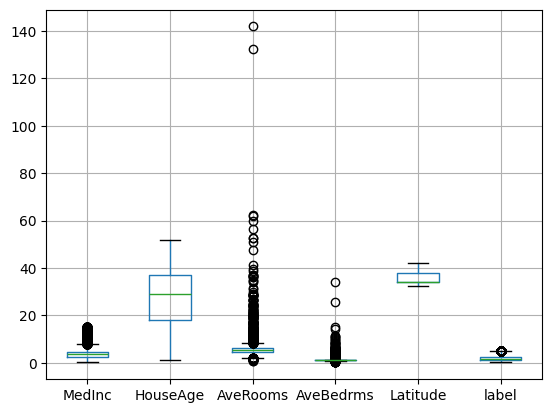

In [22]:
df.drop(['Population','AveOccup','Longitude'],axis=1).boxplot()
#df[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'label']].boxplot()

In [23]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'label'],
      dtype='object')

Create a correlation heat map

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

#calculate correlations between all features of your data frame (see Exploration lab)
corr = df.corr()

# Displaying correlations as a heatmap / correlation matrix 
corr.style.background_gradient(cmap ='coolwarm')

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
label,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


Which features correlate with label?

Which features show colinearity?

# Task 3: Data Preparation

In [25]:
#calculate correlations of features to label
df_corr_label=df.corrwith(df['label'])
df_corr_label

MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
label         1.000000
dtype: float64

In [ ]:
#keep 5 features with hightest correlation to label
df=df[df_corr_label.abs().sort_values(ascending=False).index[:6]]
df

,label,MedInc,AveRooms,Latitude,HouseAge,AveBedrms
0,4.526,8.3252,6.984127,37.88,41.0,1.023810
1,3.585,8.3014,6.238137,37.86,21.0,0.971880
2,3.521,7.2574,8.288136,37.85,52.0,1.073446
3,3.413,5.6431,5.817352,37.85,52.0,1.073059
4,3.422,3.8462,6.281853,37.85,52.0,1.081081
...,...,...,...,...,...,...
20635,0.781,1.5603,5.045455,39.48,25.0,1.133333
20636,0.771,2.5568,6.114035,39.49,18.0,1.315789
20637,0.923,1.7000,5.205543,39.43,17.0,1.120092
20638,0.847,1.8672,5.329513,39.43,18.0,1.171920


Reduce data set to first 10.000 rows

In [27]:
df=df.iloc[:10000,:]
df

,label,MedInc,AveRooms,Latitude,HouseAge,AveBedrms
0,4.526,8.3252,6.984127,37.88,41.0,1.023810
1,3.585,8.3014,6.238137,37.86,21.0,0.971880
2,3.521,7.2574,8.288136,37.85,52.0,1.073446
3,3.413,5.6431,5.817352,37.85,52.0,1.073059
4,3.422,3.8462,6.281853,37.85,52.0,1.081081
...,...,...,...,...,...,...
9995,1.645,4.0775,6.140900,39.14,10.0,1.025440
9996,1.559,4.0848,6.350394,39.13,8.0,1.091864
9997,1.702,3.6333,7.243455,39.11,7.0,1.107330
9998,2.017,3.4630,6.363636,39.08,8.0,1.166297


Split data into training and test data (7.000 training examples)

In [28]:
num_training_examples=7000

#Training Data
train_features=df.iloc[:num_training_examples,1:]
train_labels=df.iloc[:num_training_examples,0]

#Test Data (the remaining examples)
#Add lines of code to create test data (features and labels)
test_features=df.iloc[num_training_examples:,1:]
test_labels=df.iloc[num_training_examples:,0]

In [29]:
#Check if data split was successfull
#train_features
#train_labels
#test_features
test_labels

7000    1.488
7001    1.603
7002    1.582
7003    1.728
7004    1.540
        ...  
9995    1.645
9996    1.559
9997    1.702
9998    2.017
9999    1.625
Name: label, Length: 3000, dtype: float64

Fit regression model to training data and print regression coefficiants

# Task 4: Model Building

In [30]:
#Linear Regression
from sklearn import linear_model
reg = linear_model.LinearRegression()

#Fit regression model to reduced training data
reg.fit(train_features,train_labels)

#Print regression coefficiants
print("Regression coefficients: ",reg.coef_)

Regression coefficients:  [ 0.48627175 -0.15516584 -0.10547022  0.01167709  0.74397143]


Predict values for all test example

In [31]:
#Predict all test examples
ypred = reg.predict(test_features)
#Show first 10 prediction results
ypred[0:10]

array([2.21006281, 2.01081435, 2.01307818, 2.26683459, 2.28482573,
       2.46264803, 1.97138853, 2.32560565, 2.29222954, 1.91281172])

Calculate deviations in USD (two decimals) between predicted and actual label for first 10 examples. Four rounding you can use the round() function

In [32]:
print("Deviations predicted from actual value:\n",round((ypred[0:10]-test_labels.iloc[0:10])*100000,2))

Deviations predicted from actual value:
 7000    72206.28
7001    40781.43
7002    43107.82
7003    53883.46
7004    74482.57
7005    87064.80
7006    29338.85
7007    62760.56
7008    53422.95
7009    20581.17
Name: label, dtype: float64


Export training (one file including features and label) and test data (one file including features and label) for part 2 of the lab 

In [33]:
training_df=train_features
training_df['Label']=train_labels

test_df=test_features
test_df['Label']=test_labels

training_df.to_csv("Training.CSV")
test_df.to_csv("Test.CSV")